# Simulating and analysing an intensity-interferometry observation, start to finish

This notebook takes one star from catalogue lookup to a fitted angular diameter:

1. **Target selection** and sky darkness/moon proximity checks
2. **Simulation**  with `spysii`, choose array setup from spysii/data/telescope_layouts
3. **OIFITS Export**
4. **Analysis** with `oimodeler`: build the star/arbitrary SkyImage corresponding model, fit it with a least-squares minimiser and with MCMC (`emcee`), and check the residuals.
5. **Validate** the analysis with a Monte Carlo test: are the quoted error bars honest?

### Running it
Requires `spysii` (on branch feature/oifits-export) and `oimodeler`. Use an environment to `oimodeler` specifications as upgrades from `spysii`-pinned versions do not break functionality while `oimodeler` fails under some circumstances in the pinned astropy. A pip check warning is thrown by `spysii`, but can be ignored.

The example observes **γ Crv** (gam Crv) with the **CTAO-North alpha** layout (4 LSTs + 9 MSTs, 78 baselines) on a moonless night in March 2027.

## 0. Setup: one environment for spysii and oimodeler

spysii's [`environment.yml`](../environment.yml) pins `numpy=1.23.0` and `astropy=5.0.4`, which are older than oimodeler requires (`numpy>=1.26.4`, `astropy>=6.0.1`). Run the commands from the root of the spysii repository, on branch `feature/oifits-export`.

**1. Create the env** with spysii's conda dependencies from `environment.yml` (minus the numpy and astropy pins) plus oimodeler's:
```bash
mamba create -n spysii-oim -c conda-forge python=3.9 \
      "numpy>=1.26.4,<2" "astropy>=6.0.1" "scipy>=1.13.1" \
      matplotlib lmfit click pyyaml ipython pygments jupyter \
      astroquery dynesty emcee h5py pyfftw toml tqdm
mamba activate spysii-oim
```

**2. Install oimodeler**, either the development version as an editable install from a clone:
```bash
git clone https://github.com/oimodeler/oimodeler.git ../oimodeler
pip install -e ../oimodeler
```
or the latest release: `pip install oimodeler`. pip also installs `corner` here: conda-forge has no corner ≥ 2.2.3 that works with Python 3.9 and scipy ≥ 1.13, so it is left out of the mamba commands above.

**3. Install spysii.** `setup.py` pins `numpy<1.25`, so install with `--no-deps` to stop pip downgrading numpy, then add spysii's two pip-only dependencies:
```bash
pip install --no-deps .
pip install oifits coloredlogs
```
`pip install .` installs a copy, so re-run `pip install --no-deps .` after pulling spysii changes. (`pip install --no-deps -e .` links to the repo instead.)

**Already have a spysii env from `environment.yml`?** Upgrade it in place instead of step 1, then run steps 2 and 3:
```bash
mamba install -c conda-forge "numpy>=1.26.4,<2" "astropy>=6.0.1" "scipy>=1.13.1" \
      astroquery dynesty emcee h5py pyfftw toml tqdm
```

Both routes were tested, a fresh env from step 1 and an in-place upgrade of an existing spysii env: Python 3.9, numpy 1.26.4, astropy 6.0.1, scipy 1.13.1, oimodeler 1.0.1. The cell that resolves the target name (`SkyCoord.from_name`, Section 3) needs internet access.

## 1. Imports and plotting style

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)   # old escape sequences in spysii

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from cycler import cycler
import astropy.units as u
from astropy.time import Time
from astropy.io import fits
from astropy.coordinates import AltAz, get_body
from scipy.special import j1

import spysii.sim_run as sr
import oimodeler as oim

# Colour-blind-friendly cycle; set before any figure is created.
CYCLE = ['#00336A', '#E69F00', '#009E73', '#56B4E9', '#F0E442', '#D55E00', '#CC79A7']
plt.rc('axes', prop_cycle=cycler(color=CYCLE))
plt.rc('figure', dpi=110)
INK2, GRID, REF = "#52514e", "#e1e0d9", "#52514e"   # secondary ink, gridlines, reference line

def style_axes(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=INK2)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)

MAS = (1 * u.mas).to_value(u.rad)
import astropy
print(f"numpy {np.__version__} | astropy {astropy.__version__} | oimodeler {oim.__version__}")
print("spysii from", sr.__file__)
assert hasattr(sr.SimulateSiiRuns, "export_oifits"), \
    "This spysii install has no export_oifits: install it from branch feature/oifits-export (Section 0, step 3)."

numpy 1.26.4 | astropy 6.0.1 | oimodeler 1.0.1
spysii from /home/christopher/software/miniforge3/envs/spysii/lib/python3.9/site-packages/spysii/sim_run.py


## 2. Configuration
**Everything you would normally change is in this one cell**. `STELLAR_DIAMETER = None` takes the diameter from the JMDC catalogue (the measured-diameter catalogue that spysii bundles). The noise model in spysii uses `np.random`, so seeding it makes the whole notebook reproducible.

In [2]:
TARGET = "gam Crv"
OBSERVATORY = "CTA-N_alpha"        # any layout in spysii/data/telescope_layouts
WAVELENGTH = 420e-9                # m
STELLAR_DIAMETER = None            # e.g. 0.9 * u.mas; None -> JMDC catalogue
NIGHT_START = Time("2027-03-10T19:00:00", scale="utc")   # roughly sunset at La Palma; new Moon
NIGHT_LENGTH = 12 * u.hour
RUN_DURATION = 30 * u.min
MIN_ALTITUDE = 30 * u.deg          # don't observe below this
MOON_TO_STAR = 0.1                 # sky background from the Moon relative to the star

SEED = 42
np.random.seed(SEED)

HERE = Path.cwd()
OUT = HERE / "oimodeler_output"
OUT.mkdir(exist_ok=True)
OIFITS_FILE = OUT / f"{TARGET.replace(' ', '_')}_{OBSERVATORY}.oifits"

## 3. The target
`SimulateSiiRuns` resolves the name, looks up the B magnitude (Bright Star Catalogue) and the diameter (JMDC), and loads the telescope layout: positions, mirror areas, efficiencies and electronics bandwidth. The signal-to-noise model needs all of these.

In [3]:
sim = sr.SimulateSiiRuns(TARGET, stellar_diameter=STELLAR_DIAMETER, zbc_norm=1.,
                         observatory_name=OBSERVATORY, wavelength=WAVELENGTH)
D_TRUE = sim.stellar_diameter.to_value(u.mas)
tel_names = sim.observatory["telescope_names"]

print(f"target       : {TARGET}  (RA {sim.target_skycoord.ra.deg:.3f}°, Dec {sim.target_skycoord.dec.deg:.3f}°)")
print(f"B magnitude  : {sim.target_b_mag}")
print(f"diameter     : {D_TRUE} mas  (the 'truth' of this simulation)")
print(f"array        : {OBSERVATORY}: " + ", ".join(
      f"{n} ({a} m²)" for n, a in zip(tel_names, sim.observatory["constants"]["area"])))
print(f"pairs        : {len(sim.telescope_pair_combinations)} baselines")
first_null = 1.22 * WAVELENGTH / (D_TRUE * MAS)
print(f"first V² null of a {D_TRUE} mas disk at {WAVELENGTH*1e9:.0f} nm: B ≈ {first_null:.0f} m")

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72
target       : gam Crv  (RA 183.952°, Dec -17.542°)
B magnitude  : 2.4800000190734863
diameter     : 0.72 mas  (the 'truth' of this simulation)
array        : CTA-N_alpha: LST1 (370 m²), LST2 (370 m²), LST3 (370 m²), LST4 (370 m²), MST1 (88 m²), MST2 (88 m²), MST3 (88 m²), MST4 (88 m²), MST5 (88 m²), MST7 (88 m²), MST8 (88 m²), MST10 (88 m²), MST15 (88 m²)
pairs        : 78 baselines
first V² null of a 0.72 mas disk at 420 nm: B ≈ 147 m


## 4. Planning the night
We sample the night every few minutes and keep only the times when the Sun is below −18° (astronomical darkness) and the target is above `MIN_ALTITUDE`. The usable window is cut into back-to-back runs of `RUN_DURATION`.

In [4]:
t_grid = NIGHT_START + np.arange(0, NIGHT_LENGTH.to_value(u.min), 5) * u.min
frame = AltAz(obstime=t_grid, location=sim.site)
alt_star = sim.target_skycoord.transform_to(frame).alt
alt_sun = get_body("sun", t_grid).transform_to(frame).alt
alt_moon = get_body("moon", t_grid).transform_to(frame).alt
usable = (alt_sun < -18 * u.deg) & (alt_star > MIN_ALTITUDE)

# Back-to-back runs that fit entirely inside the usable window
run_starts = []
t = t_grid[usable][0]
while t + RUN_DURATION <= t_grid[usable][-1] + 5 * u.min:
    i0, i1 = np.searchsorted(t_grid.mjd, [t.mjd, (t + RUN_DURATION).mjd])
    if usable[i0:i1].all():
        run_starts.append(t)
        t = t + RUN_DURATION
    else:
        t = t + 5 * u.min
run_starts = Time(run_starts)
# spysii's fast simulation treats a run as instantaneous: evaluate it at the run midpoint
run_mids = run_starts + RUN_DURATION / 2
print(f"{len(run_starts)} runs of {RUN_DURATION}  ->  {len(run_starts) * RUN_DURATION.to(u.h):.1f} on target")
print("first run starts", run_starts[0].iso[:16], "UTC; last run ends", (run_starts[-1] + RUN_DURATION).iso[:16], "UTC")

10 runs of 30.0 min  ->  5.0 h on target
first run starts 2027-03-10 23:40 UTC; last run ends 2027-03-11 04:40 UTC


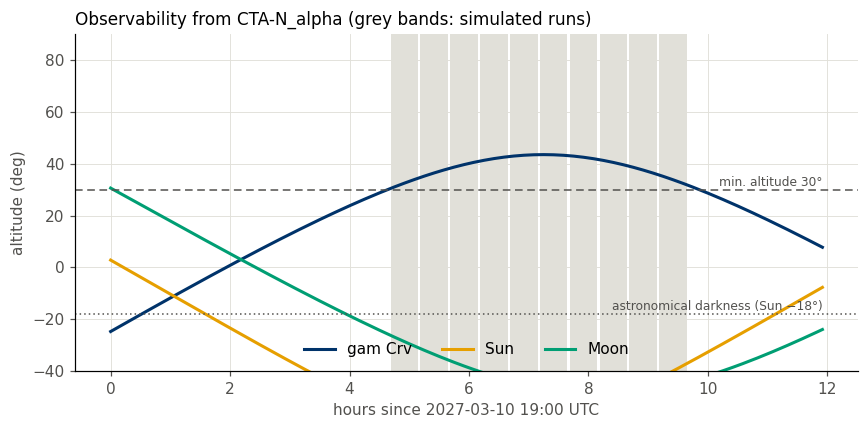

In [5]:
hours = (t_grid - NIGHT_START).to_value(u.h)
fig, ax = plt.subplots(figsize=(8, 4))
for t0 in run_starts:
    h0 = (t0 - NIGHT_START).to_value(u.h)
    ax.axvspan(h0 + 0.02, h0 + RUN_DURATION.to_value(u.h) - 0.02, color=GRID, lw=0, zorder=0)
ax.plot(hours, alt_star, lw=2, label=TARGET)
ax.plot(hours, alt_sun, lw=2, label="Sun")
ax.plot(hours, alt_moon, lw=2, label="Moon")
ax.axhline(MIN_ALTITUDE.value, color=REF, lw=1, ls=(0, (5, 3)))
ax.axhline(-18, color=REF, lw=1, ls=(0, (1, 2)))
ax.text(hours[-1], MIN_ALTITUDE.value + 1.5, f"min. altitude {MIN_ALTITUDE.value:.0f}°", ha="right", color=INK2, fontsize=8)
ax.text(hours[-1], -16.5, "astronomical darkness (Sun −18°)", ha="right", color=INK2, fontsize=8)
ax.set_ylim(-40, 90)
ax.set_xlabel(f"hours since {NIGHT_START.iso[:16]} UTC", color=INK2)
ax.set_ylabel("altitude (deg)", color=INK2)
ax.set_title(f"Observability from {OBSERVATORY} (grey bands: simulated runs)", loc="left", fontsize=11)
style_axes(ax)
ax.legend(frameon=False, loc="lower center", ncol=3)
fig.tight_layout()

## 5. Simulating the observation with spysii
For each run and each telescope pair, spysii:

* projects the baseline onto the sky plane at that hour angle, which gives $(u, v)$ in metres;
* evaluates the model $V^2$ of the selected SkyImage or UD at that projected baseline;
* computes the expected S/N from the telescope areas, efficiencies, bandwidth, star brightness (corrected for airmass), Moon background and run length;
* draws the "measured" $V^2$ from a Gaussian around the model with $\sigma = V^2/(S/N)$.


In [6]:
sim.reset()
sim.simulate_observations(run_mids, RUN_DURATION, moon_to_star_ratio=MOON_TO_STAR, fast_simulation=True)

# Flatten the list of runs into one row per (run, pair) for plotting
rows = [(f"{p[0]}–{p[1]}", r["datetime"], r["U"][i], r["V"][i], r["baseline"][i],
         r["squared_visibilities"][i], r["sim_g2"][i], r["sim_g2_error"][i])
        for r in sim.simulated_runs for i, p in enumerate(r["telescope_pair"])]
def pair_type(a, b):
    # Group baselines by telescope type, e.g. "LST2"/"MST7" -> "LST–MST"
    return "–".join(sorted(n.rstrip("0123456789") for n in (a, b)))

pair_lab = np.array([pair_type(*r[0].split("–")) for r in rows])
u_m, v_m, B, v2_true, v2, v2_err = (np.array([r[k] for r in rows], float) for k in range(2, 8))
# One colour per baseline type
PAIRS = list(dict.fromkeys(pair_lab))
assert len(PAIRS) <= len(CYCLE), "more baseline types than colours: group them further"
STYLE = {p: (CYCLE[i], m) for i, (p, m) in enumerate(zip(PAIRS, "os^D<>v"))}

print(f"{len(rows)} V² measurements ({len(sim.simulated_runs)} runs × {len(sim.telescope_pair_combinations)} baselines)\n")
print(f"{'baseline type':14s} {'pairs':>5s} {'B range (m)':>14s} {'median σ(V²)':>13s}")
for p in PAIRS:
    k = pair_lab == p
    n_pairs = len({r[0] for r, kk in zip(rows, k) if kk})
    print(f"{p:14s} {n_pairs:5d} {B[k].min():6.1f} – {B[k].max():5.1f} {np.median(v2_err[k]):13.4f}")

780 V² measurements (10 runs × 78 baselines)

baseline type  pairs    B range (m)  median σ(V²)
LST–LST            6   76.3 – 179.4        0.0051
LST–MST           36   38.9 – 366.3        0.0105
MST–MST           36   94.0 – 499.8        0.0216


### u-v coverage and the measured $V^2$
Earth rotation sweeps each baseline along an arc in the $(u, v)$ plane. Each measurement also gives its point mirrored through the origin, $(-u, -v)$, because $V^2$ is centrally symmetric (shown hollow).

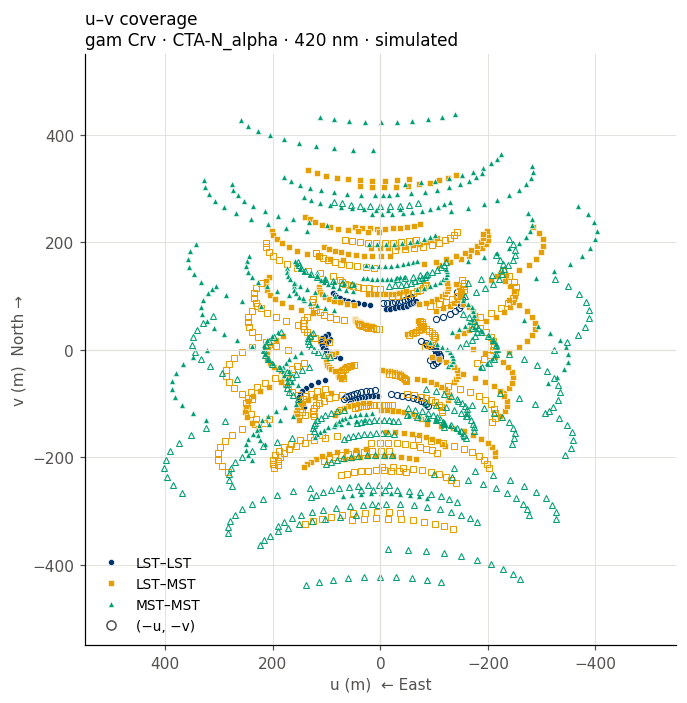

In [7]:
SUB = f"{TARGET} · {OBSERVATORY} · {WAVELENGTH*1e9:.0f} nm · simulated"

fig, ax = plt.subplots(figsize=(6.5, 6.5))
for p in PAIRS:
    k = pair_lab == p
    c, m = STYLE[p]
    ax.plot(u_m[k], v_m[k], m, color=c, mec="white", mew=0.4, ms=4, ls="none", label=p)
    ax.plot(-u_m[k], -v_m[k], m, color=c, mfc="none", mew=0.7, ms=4, ls="none")
lim = 1.1 * B.max()
ax.set_xlim(lim, -lim)           # East to the left, as on the sky
ax.set_ylim(-lim, lim)
ax.set_aspect("equal")
ax.axhline(0, color=GRID, lw=0.8); ax.axvline(0, color=GRID, lw=0.8)
ax.set_xlabel("u (m)  ← East", color=INK2); ax.set_ylabel("v (m)  North →", color=INK2)
ax.set_title("u–v coverage\n" + SUB, loc="left", fontsize=11)
style_axes(ax)
h, _ = ax.get_legend_handles_labels()
h.append(Line2D([], [], marker="o", mfc="none", mec=INK2, ls="none", label="(−u, −v)"))
ax.legend(handles=h, frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()

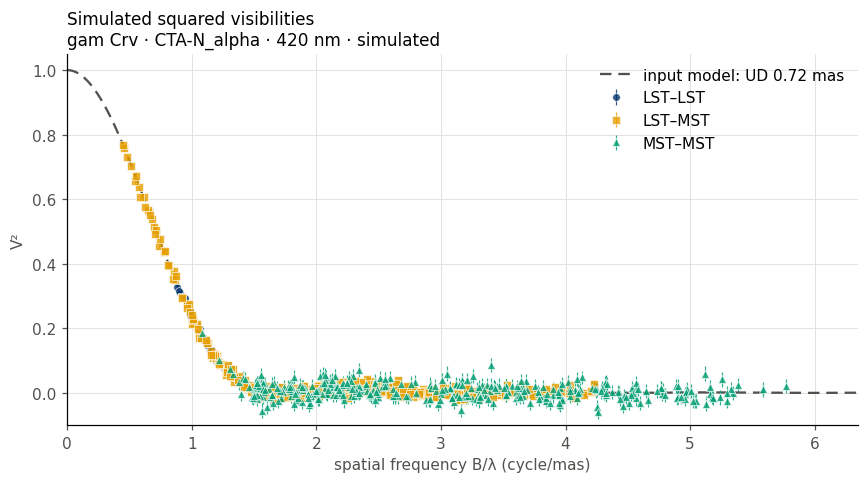

In [8]:
def ud_v2(b_over_lambda_mas, d):
    # V² of a uniform disk; spatial frequency in cycle/mas, d in mas
    x = np.pi * b_over_lambda_mas * d
    return (2 * j1(x) / x) ** 2

sf = B / WAVELENGTH * MAS                                # spatial frequency, cycle/mas
f_grid = np.linspace(1e-3, 1.1 * sf.max(), 500)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(f_grid, ud_v2(f_grid, D_TRUE), color=REF, lw=1.5, ls=(0, (5, 3)), label=f"input model: UD {D_TRUE} mas")
for p in PAIRS:
    k = pair_lab == p
    c, m = STYLE[p]
    ax.errorbar(sf[k], v2[k], v2_err[k], fmt=m, color=c, mec="white", mew=0.5, ms=5,
                elinewidth=0.8, capsize=0, alpha=0.8, label=p)
ax.set_xlim(0, f_grid.max()); ax.set_ylim(-0.1, 1.05)
ax.set_xlabel("spatial frequency B/λ (cycle/mas)", color=INK2)
ax.set_ylabel("V²", color=INK2)
ax.set_title("Simulated squared visibilities\n" + SUB, loc="left", fontsize=11)
style_axes(ax)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()

## 6. Export to OIFITS
`export_oifits` writes the standard tables: `OI_TARGET`, `OI_ARRAY` (telescope positions and diameters), `OI_WAVELENGTH` (one monochromatic channel) and `OI_VIS2` (one row per measurement, with $u$, $v$, $V^2$, $\sigma$ and the station indices). From here on the analysis reads only this file. Any OIFITS-aware tool could take over at this point.

In [9]:
sim.export_oifits(str(OIFITS_FILE), overwrite=True)
with fits.open(OIFITS_FILE) as hdul:
    hdul.info()
    print()
    print(hdul["OI_VIS2"].columns)

Filename: /home/christopher/Documents/software/spysii/spysii/notebooks/oimodeler_output/gam_Crv_CTA-N_alpha.oifits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   ()      
  1  OI_WAVELENGTH    1 BinTableHDU     17   1R x 2C   [1E, 1E]   
  2  OI_TARGET     1 BinTableHDU     56   1R x 17C   [1I, 16A, 1D, 1D, 1E, 1D, 1D, 1D, 8A, 8A, 1D, 1D, 1D, 1D, 1E, 1E, 16A]   
  3  OI_ARRAY      1 BinTableHDU     27   13R x 5C   [16A, 16A, 1I, 1E, 3D]   
  4  OI_VIS2       1 BinTableHDU     39   780R x 10C   [1I, 1D, 1D, 1D, 1D, 1D, 1D, 1D, 2I, 1L]   



ColDefs(
    name = 'TARGET_ID'; format = '1I'
    name = 'TIME'; format = '1D'; unit = 'SECONDS'
    name = 'MJD'; format = '1D'; unit = 'DAY'
    name = 'INT_TIME'; format = '1D'; unit = 'SECONDS'
    name = 'VIS2DATA'; format = '1D'
    name = 'VIS2ERR'; format = '1D'
    name = 'UCOORD'; format = '1D'; unit = 'METERS'
    name = 'VCOORD'; format = '1D'; unit = 'METERS'
    name = 'STA_INDEX'; format = '2I'; null = -1
    name = 'FLAG'; format = '1L'
)


## 7. Loading the data into oimodeler
`oimData` reads the OIFITS file(s). oimodeler's own plotting axes (`projection="oimAxes"`) understand OIFITS quantities directly, which makes a handy sanity check that the file was read as intended.

oimData containing 1 file(s)
gam_Crv_CTA-N_alpha.oifits
	OI_VIS2(780,)
		VIS2DATA



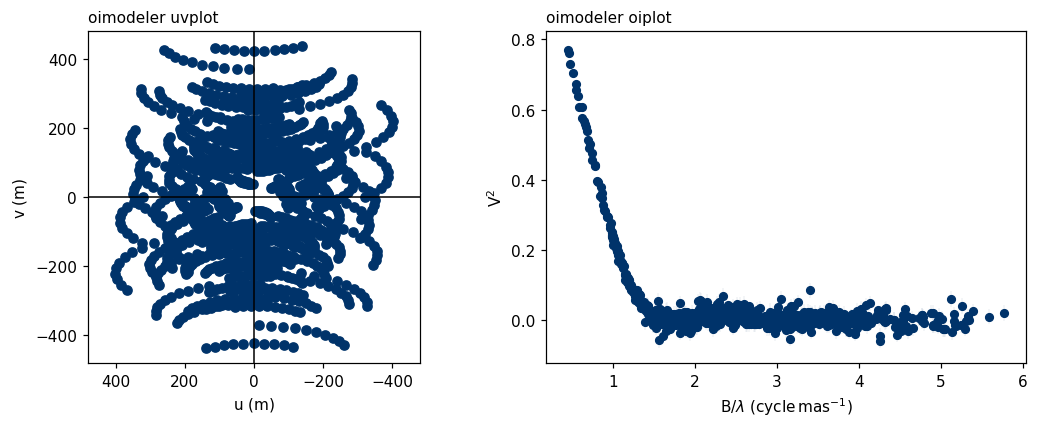

In [10]:
data = oim.oimData(str(OIFITS_FILE))
print(data)

fig = plt.figure(figsize=(10, 4))
ax1 = fig.add_subplot(1, 2, 1, projection="oimAxes")
ax2 = fig.add_subplot(1, 2, 2, projection="oimAxes")
ax1.uvplot(data.data, color=CYCLE[0], unit="m", showLegend=False)
ax2.oiplot(data.data, "SPAFREQ", "VIS2DATA", xunit="cycle/mas", errorbar=True, color=CYCLE[0],
           marker="o", ls="", ms=5, kwargs_error=dict(alpha=0.6))
ax1.set_title("oimodeler uvplot", loc="left", fontsize=10)
ax2.set_title("oimodeler oiplot", loc="left", fontsize=10)
fig.tight_layout()

### Cross-check: does oimodeler see the same star that spysii simulated?
We put the **input** model, the same brightness distribution spysii simulated (here a uniform disk with the true diameter), into an `oimSimulator` and compare its $V^2$ at the exported $(u, v)$ points with spysii's noiseless $V^2$. Agreement to rounding error confirms that the OIFITS export, the sign and unit conventions and the wavelength all made it through intact. The $\chi^2_r$ of the input model on the noisy data should be close to 1.

In [11]:
truth = oim.oimModel(oim.oimUD(d=D_TRUE))
sim_truth = oim.oimSimulator(data=data, model=truth)
sim_truth.compute(computeChi2=True, computeSimulatedData=True, dataTypes=["VIS2DATA"])
v2_oim = sim_truth.simulatedData.data[0]["OI_VIS2"].data["VIS2DATA"].ravel()

print(f"max |V²(oimodeler) − V²(spysii, noiseless)| = {np.max(np.abs(v2_oim - v2_true)):.2e}")
print(f"χ²_r of the input model on the simulated data = {sim_truth.chi2r:.3f}  (expect ≈ 1 ± {np.sqrt(2/len(v2)):.2f})")

max |V²(oimodeler) − V²(spysii, noiseless)| = 4.95e-07
χ²_r of the input model on the simulated data = 0.978  (expect ≈ 1 ± 0.05)


## 8. The model
oimodeler fits whatever brightness distribution you build from its components; choosing that model is up to you. A single-wavelength $V^2$ data set without closure phases constrains only the centro-symmetric part of the image. Useful models therefore include uniform and limb-darkened disks (`oimUD`, `oimPowerLawLDD`, …), elliptical disks (`oimEllipse`), gravity-darkened fast rotators (`oimFastRotator`), Gaussians and rings, and binaries built by adding two components, with the companion's separation and position angle free.

Since spysii simulated a uniform disk here, this example fits a **uniform disk (UD)**, which has a single free parameter, the diameter $d$. Its flux is normalised to 1, so $V^2(0) = 1$, which matches the `zbc_norm = 1` used in the simulation. For another model, change `ud_model()` below and the parameter the helpers vary; the scan, fits, diagnostics and Monte Carlo steps carry over.

The small helpers below build the model and wrap the operations the rest of the notebook repeats: scanning $\chi^2$ over a grid of the parameter, running oimodeler's least-squares fitter from a given start, and computing the textbook error bar from the curvature of $\chi^2$ at its minimum, $\sigma_d = \sqrt{2 / (\partial^2\chi^2/\partial d^2)}$ (the $\Delta\chi^2 = 1$ error).

{'c1_UD_d': oimParam at 0x7d9de27d3b80 : d=0.5 ± 0 mas range=[0.05,3.0] free=True }


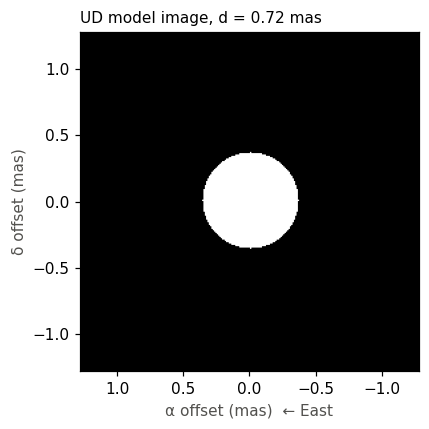

In [12]:
def ud_model(d0=0.5):
    ud = oim.oimUD(d=d0)
    ud.params["d"].set(min=0.05, max=3.0)
    m = oim.oimModel(ud)
    m.normalizeFlux()
    return ud, m

def chi2r_scan(data, d_grid):
    # Reduced χ² of a UD model at each diameter in d_grid
    ud, m = ud_model()
    s = oim.oimSimulator(data=data, model=m)
    out = np.empty(len(d_grid))
    for i, d in enumerate(d_grid):
        ud.params["d"].value = d
        s.compute(computeChi2=True, dataTypes=["VIS2DATA"])
        out[i] = s.chi2r
    return out

def fit_minimize(data, d0):
    ud, m = ud_model(d0)
    f = oim.oimFitterMinimize(data, m, dataTypes=["VIS2DATA"])
    f.prepare()
    f.run()
    (d,), (e,) = f.getResults()
    return d, e, f

def curvature_error(data, d, h=1e-3):
    # σ_d = sqrt(2 / χ²''), from a central finite difference of the total (not reduced) χ²
    ud, m = ud_model()
    s = oim.oimSimulator(data=data, model=m)
    c = []
    for di in (d - h, d, d + h):
        ud.params["d"].value = di
        s.compute(computeChi2=True, dataTypes=["VIS2DATA"])
        c.append(s.chi2)
    return np.sqrt(2 * h**2 / (c[0] - 2 * c[1] + c[2]))

ud, model = ud_model()
print(model.getFreeParameters())

# What the model looks like on the sky
fig, ax = plt.subplots(figsize=(4, 4))
ud.params["d"].value = D_TRUE
img = model.getImage(256, 0.01, wl=WAVELENGTH)
ext = np.array([1, -1, -1, 1]) * 256 * 0.01 / 2
ax.imshow(img, extent=ext, origin="lower", cmap="Greys_r")
ax.set_xlabel("α offset (mas)  ← East", color=INK2); ax.set_ylabel("δ offset (mas)", color=INK2)
ax.set_title(f"UD model image, d = {D_TRUE} mas", loc="left", fontsize=10)
fig.tight_layout()

## 9. Look before you fit: the $\chi^2$ landscape
A local optimiser finds *a* minimum of $\chi^2$, not necessarily *the* minimum. When the baselines sample only the region past the first null of $V^2$, models of quite different sizes all predict similarly low $V^2$, and $\chi^2(d)$ can have **several minima**. An optimiser started in the wrong basin converges to a wrong diameter with a small, confident error bar. For example, simulating γ Cas with `"MAGIC-LST"` (shortest baseline about 55 m, already well down the main lobe) and starting the fit at 0.5 mas gives 1.73 mas instead of the true 0.9 mas.

Whether this bites depends on the $(u,v)$ coverage. The scan is done here because this is a one-parameter UD demonstration, where it costs almost nothing. For more complex or time-dependent models it becomes prohibitively expensive and should be turned off.

naive fit from 0.5 mas: d = 0.7199 mas, χ²_r = 0.98
-> found the global minimum: with this coverage the landscape has a single deep basin


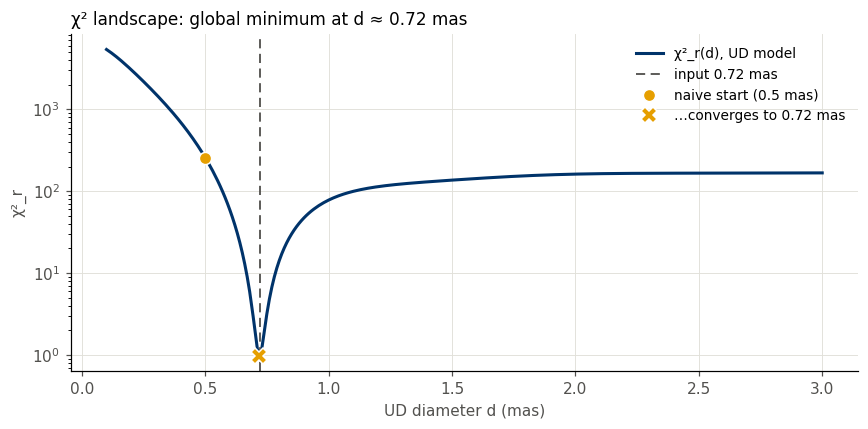

In [13]:
D_GRID = np.linspace(0.1, 3.0, 291)
chi2r_grid = chi2r_scan(data, D_GRID)
d_grid_best = D_GRID[np.argmin(chi2r_grid)]
# The minimum can be much narrower than the grid step: add a fine grid around it for plotting
d_fine = np.linspace(d_grid_best - 0.03, d_grid_best + 0.03, 121)
D_PLOT = np.concatenate([D_GRID, d_fine]); order = np.argsort(D_PLOT)
D_PLOT, chi2r_plot = D_PLOT[order], np.concatenate([chi2r_grid, chi2r_scan(data, d_fine)])[order]

d_naive, e_naive, _ = fit_minimize(data, d0=0.5)     # what happens without the scan
chi2r_naive = chi2r_scan(data, [d_naive])[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(D_PLOT, chi2r_plot, lw=2, label="χ²_r(d), UD model")
ax.axvline(D_TRUE, color=REF, lw=1.2, ls=(0, (5, 3)), label=f"input {D_TRUE} mas")
ax.plot([0.5], [np.interp(0.5, D_GRID, chi2r_grid)], "o", color=CYCLE[1], ms=8, mec="white", label="naive start (0.5 mas)")
ax.plot([d_naive], [chi2r_naive], "X", color=CYCLE[1], ms=10, mec="white", label=f"…converges to {d_naive:.2f} mas")
ax.set_yscale("log")
ax.set_xlabel("UD diameter d (mas)", color=INK2); ax.set_ylabel("χ²_r", color=INK2)
ax.set_title(f"χ² landscape: global minimum at d ≈ {d_grid_best:.2f} mas", loc="left", fontsize=11)
style_axes(ax)
ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.tight_layout()
trapped = abs(d_naive - d_grid_best) > 2 * (D_GRID[1] - D_GRID[0])
print(f"naive fit from 0.5 mas: d = {d_naive:.4f} mas, χ²_r = {chi2r_naive:.2f}")
print("-> trapped in a local minimum!" if trapped else
      f"-> found the global minimum: with this coverage the landscape has a single deep basin")

## 10. Fit 1: least-squares (`oimFitterMinimize`)
Starting from the global minimum of the grid, the minimiser refines $d$. It is fast and gives a point estimate. The error it prints comes from the BFGS inverse-Hessian approximation of $\chi^2$. We also compute the curvature error alongside it, and Section 13 tests which of the two can be trusted.

In [14]:
d_min, e_min, fit_min = fit_minimize(data, d0=d_grid_best)
fit_min.printResults()
chi2r_min = fit_min.simulator.chi2r
e_curv = curvature_error(data, d_min)
print(f"curvature (Δχ² = 1) error: ± {e_curv:.5f} mas   (minimiser / curvature = {e_min / e_curv:.2f})")

c1_UD_d = 0.71987 ± 0.00048 mas
chi2r = 0.97682
curvature (Δχ² = 1) error: ± 0.00068 mas   (minimiser / curvature = 0.70)


## 11. Fit 2: Bayesian MCMC (`oimFitterEmcee`)
`emcee` samples the posterior of the free parameters, $p(\theta \mid \text{data}) \propto \exp(-\chi^2/2)$ (here $\theta = d$), with a uniform prior inside the parameter bounds. Walkers are started in a Gaussian ball around the least-squares solution (`init="gaussian"`). If you start them uniformly over $[0.05, 3]$ mas instead and the landscape has a secondary minimum (Section 9), a few walkers can get stranded there and never leave it. We discard the burn-in and report the median with the 16th and 84th percentiles.

In [15]:
NWALKERS, NSTEPS, DISCARD = 16, 1500, 300
ud, model = ud_model(d_min)
ud.params["d"].error = 5 * e_min          # width of the initial walker ball
fit_mc = oim.oimFitterEmcee(data, model, nwalkers=NWALKERS, dataTypes=["VIS2DATA"])
fit_mc.prepare(init="gaussian")
fit_mc.run(nsteps=NSTEPS, progress=False)
(d_mc,), (el_mc,), (eu_mc,), _ = fit_mc.getResults(mode="median", discard=DISCARD)
e_mc = (el_mc + eu_mc) / 2
chi2r_mc = fit_mc.simulator.chi2r
print(f"d = {d_mc:.4f} −{el_mc:.4f} +{eu_mc:.4f} mas   χ²_r = {chi2r_mc:.3f}")
print(f"mean acceptance fraction: {np.mean(fit_mc.sampler.acceptance_fraction):.2f}")

d = 0.7199 −0.0007 +0.0007 mas   χ²_r = 0.977
mean acceptance fraction: 0.56


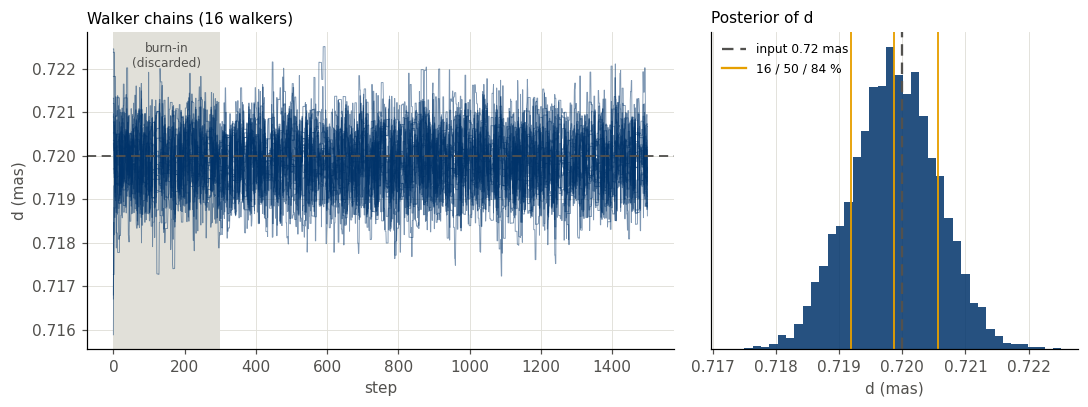

In [16]:
chain = fit_mc.sampler.get_chain()[:, :, 0]               # (steps, walkers)
flat = fit_mc.sampler.get_chain(discard=DISCARD, flat=True)[:, 0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax1.plot(chain, color=CYCLE[0], lw=0.6, alpha=0.5)
ax1.axvspan(0, DISCARD, color=GRID, lw=0, zorder=0)
ax1.axhline(D_TRUE, color=REF, lw=1.2, ls=(0, (5, 3)))
ax1.text(DISCARD / 2, 0.97, "burn-in\n(discarded)", ha="center", va="top", color=INK2, fontsize=8,
         transform=ax1.get_xaxis_transform())
ax1.set_xlabel("step", color=INK2); ax1.set_ylabel("d (mas)", color=INK2)
ax1.set_title(f"Walker chains ({NWALKERS} walkers)", loc="left", fontsize=10)
style_axes(ax1)

ax2.hist(flat, bins=40, color=CYCLE[0], alpha=0.85)
ax2.axvline(D_TRUE, color=REF, lw=1.5, ls=(0, (5, 3)), label=f"input {D_TRUE} mas")
for q in np.percentile(flat, [16, 50, 84]):
    ax2.axvline(q, color=CYCLE[1], lw=1.2)
ax2.plot([], [], color=CYCLE[1], label="16 / 50 / 84 %")
ax2.set_xlabel("d (mas)", color=INK2); ax2.set_yticks([])
ax2.set_title("Posterior of d", loc="left", fontsize=10)
style_axes(ax2)
ax2.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()

## 12. Fit diagnostics: data, model and residuals
A good fit has normalised residuals $(V^2_\text{obs} - V^2_\text{model})/\sigma$ scattered around zero with unit spread, with no trend against baseline and no single pair consistently off.

residuals: mean -0.01, std 0.99  (expect 0, 1)


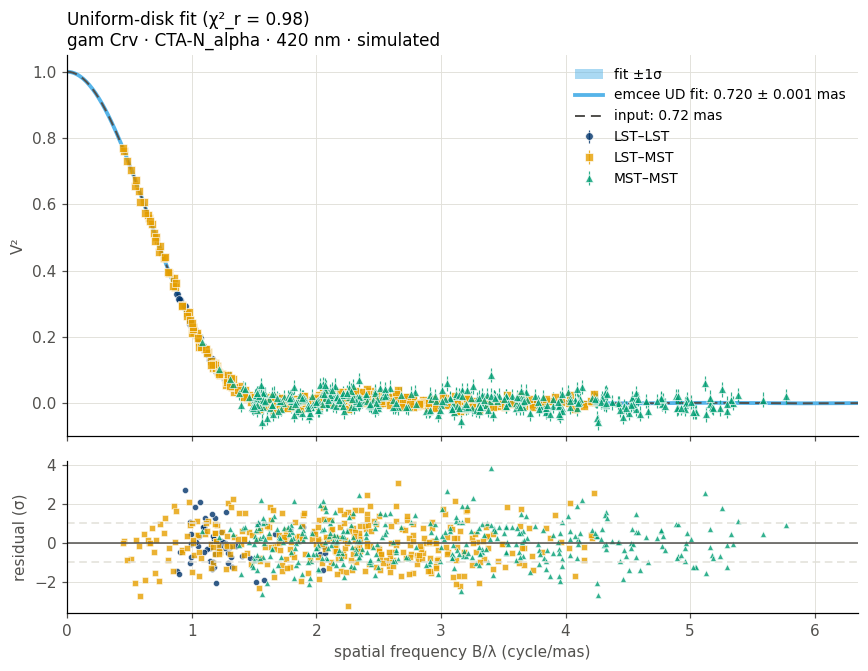

In [17]:
ud.params["d"].value = d_mc
sim_best = oim.oimSimulator(data=data, model=model)
sim_best.compute(computeChi2=True, computeSimulatedData=True, dataTypes=["VIS2DATA"])
vd = data.data[0]["OI_VIS2"].data
v2_obs, v2_e = vd["VIS2DATA"].ravel(), vd["VIS2ERR"].ravel()
v2_mod = sim_best.simulatedData.data[0]["OI_VIS2"].data["VIS2DATA"].ravel()
sf_obs = np.hypot(vd["UCOORD"], vd["VCOORD"]) / WAVELENGTH * MAS
sta = {int(r["STA_INDEX"]): r["STA_NAME"] for r in data.data[0]["OI_ARRAY"].data}
lab_obs = np.array([pair_type(sta[a], sta[b]) for a, b in vd["STA_INDEX"]])
resid = (v2_obs - v2_mod) / v2_e

FIT_C = CYCLE[len(PAIRS)]                # next free cycle colour after the baselines
band = np.array([ud_v2(f_grid, d) for d in np.linspace(d_mc - el_mc, d_mc + eu_mc, 41)])

fig, (ax, axr) = plt.subplots(2, 1, figsize=(8, 6.2), sharex=True, gridspec_kw=dict(height_ratios=[3, 1.2]))
ax.fill_between(f_grid, band.min(0), band.max(0), color=FIT_C, alpha=0.5, lw=0, label="fit ±1σ")
ax.plot(f_grid, ud_v2(f_grid, d_mc), color=FIT_C, lw=2.5, label=f"emcee UD fit: {d_mc:.3f} ± {e_mc:.3f} mas")
ax.plot(f_grid, ud_v2(f_grid, D_TRUE), color=REF, lw=1.3, ls=(0, (5, 3)), label=f"input: {D_TRUE} mas")
for p in PAIRS:
    k = lab_obs == p
    c, m = STYLE[p]
    ax.errorbar(sf_obs[k], v2_obs[k], v2_e[k], fmt=m, color=c, mec="white", mew=0.5, ms=5,
                elinewidth=0.8, capsize=0, alpha=0.8, label=p, zorder=4)
    axr.plot(sf_obs[k], resid[k], m, color=c, mec="white", mew=0.4, ms=4, alpha=0.8)
ax.set_ylim(-0.1, 1.05); ax.set_ylabel("V²", color=INK2)
ax.set_title(f"Uniform-disk fit (χ²_r = {sim_best.chi2r:.2f})\n" + SUB, loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right", fontsize=9)
axr.axhline(0, color=REF, lw=1)
for s in (-1, 1):
    axr.axhline(s, color=GRID, lw=1, ls=(0, (5, 3)))
axr.set_xlim(0, f_grid.max())
axr.set_xlabel("spatial frequency B/λ (cycle/mas)", color=INK2); axr.set_ylabel("residual (σ)", color=INK2)
for a in (ax, axr):
    style_axes(a)
fig.tight_layout()
print(f"residuals: mean {resid.mean():+.2f}, std {resid.std(ddof=1):.2f}  (expect 0, 1)")

## 13. Are the error bars honest? A Monte Carlo test
One noisy realisation cannot tell us whether a quoted $\pm\sigma$ is right. So we keep the same night, the same $(u,v)$ points and the same per-point errors, and redraw the noise many times (`sim.randomize_simulation()`). Each realisation goes through the **full chain**: OIFITS export → `oimData` → $\chi^2$ scan → least-squares fit. We then compare:

* the **scatter** of the fitted parameter (here the diameter) across realisations (the true uncertainty), with
* the **uncertainty each method reports** on a single realisation.

The **pull** $(d_\text{fit} - d_\text{true})/\sigma_\text{reported}$ should have mean 0 (no bias) and standard deviation 1 (honest errors).

What to expect: `oimFitterMinimize` reports $\sqrt{\mathrm{diag}(H^{-1})}$, where $H$ is the Hessian of $\chi^2$. The covariance, though, is $2H^{-1}$ (the inverse Hessian of $\tfrac12\chi^2$), so its errors should come out about $\sqrt2$ too small. On top of that, BFGS's $H^{-1}$ is only an approximation built up over the iterations. When the fit starts close to the minimum and stops after two or three steps, it can be wildly off. The curvature error has neither problem.

In [18]:
N_MC = 200
D_GRID_MC = np.linspace(0.1, 3.0, 146)                # coarser than §9, still fine enough to find the right basin
mc_file = OUT / "_mc_realisation.oifits"
saved = [dict(r) for r in sim.simulated_runs]           # keep the realisation analysed above
d_fit_mc, e_fit_mc, e_curv_mc = np.empty(N_MC), np.empty(N_MC), np.empty(N_MC)
for n in range(N_MC):
    sim.randomize_simulation()
    sim.export_oifits(str(mc_file), overwrite=True)
    data_n = oim.oimData(str(mc_file))
    d0 = D_GRID_MC[np.argmin(chi2r_scan(data_n, D_GRID_MC))]
    d_fit_mc[n], e_fit_mc[n], _ = fit_minimize(data_n, d0)
    e_curv_mc[n] = curvature_error(data_n, d_fit_mc[n])
sim.simulated_runs = saved
mc_file.unlink()

sigma_true = d_fit_mc.std(ddof=1)
pull_min = (d_fit_mc - D_TRUE) / e_fit_mc
pull_curv = (d_fit_mc - D_TRUE) / e_curv_mc
robust_std = lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))    # insensitive to outliers
n_bad = np.sum(e_fit_mc < 0.5 * np.median(e_fit_mc))

print(f"mean fitted d                 : {d_fit_mc.mean():.4f} mas  (input {D_TRUE}; bias {d_fit_mc.mean()-D_TRUE:+.4f} ± {sigma_true/np.sqrt(N_MC):.4f})")
print(f"actual scatter σ(d)           : {sigma_true:.4f} mas\n")
print(f"{'error estimate':24s} {'median σ':>9s} {'scatter/σ':>10s} {'pull mean':>10s} {'pull std':>9s}")
print(f"{'minimiser (BFGS H⁻¹)':24s} {np.median(e_fit_mc):9.4f} {sigma_true/np.median(e_fit_mc):10.2f} "
      f"{pull_min.mean():+10.2f} {pull_min.std(ddof=1):9.2f}   (robust std {robust_std(pull_min):.2f})")
print(f"{'curvature, Δχ² = 1':24s} {np.median(e_curv_mc):9.4f} {sigma_true/np.median(e_curv_mc):10.2f} "
      f"{pull_curv.mean():+10.2f} {pull_curv.std(ddof=1):9.2f}")
print(f"{'emcee (one run, §11)':24s} {e_mc:9.4f} {sigma_true/e_mc:10.2f}")
print(f"\n{n_bad}/{N_MC} realisations where the BFGS error is < half its median (the outliers in its pull)")

mean fitted d                 : 0.7200 mas  (input 0.72; bias -0.0000 ± 0.0001)
actual scatter σ(d)           : 0.0007 mas

error estimate            median σ  scatter/σ  pull mean  pull std
minimiser (BFGS H⁻¹)        0.0005       1.53      -5.40     20.55   (robust std 1.54)
curvature, Δχ² = 1          0.0007       1.08      -0.04      1.08
emcee (one run, §11)        0.0007       1.08

20/200 realisations where the BFGS error is < half its median (the outliers in its pull)


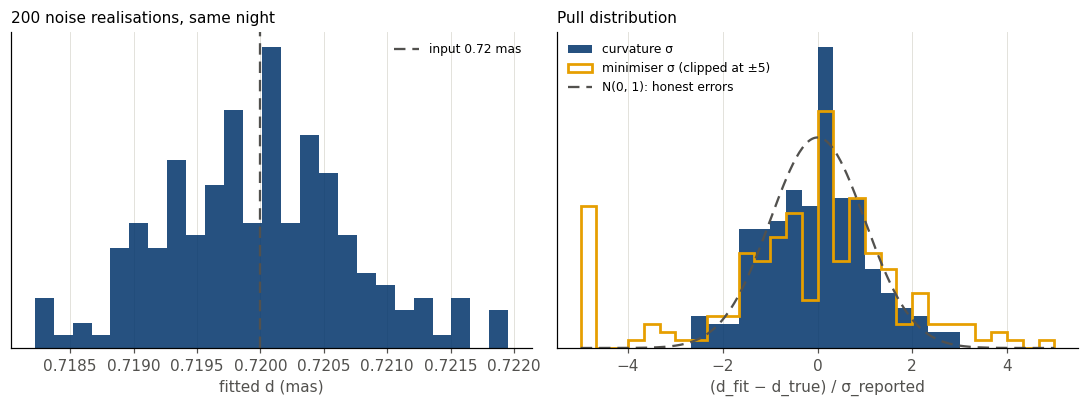

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.hist(d_fit_mc, bins=25, color=CYCLE[0], alpha=0.85)
ax1.axvline(D_TRUE, color=REF, lw=1.5, ls=(0, (5, 3)), label=f"input {D_TRUE} mas")
ax1.set_xlabel("fitted d (mas)", color=INK2); ax1.set_yticks([])
ax1.set_title(f"{N_MC} noise realisations, same night", loc="left", fontsize=10)
style_axes(ax1); ax1.legend(frameon=False, fontsize=8)

x = np.linspace(-5, 5, 300)
gauss = lambda s: np.exp(-0.5 * (x / s) ** 2) / (s * np.sqrt(2 * np.pi))
bins = np.linspace(-5, 5, 31)
ax2.hist(np.clip(pull_curv, -5, 5), bins=bins, density=True, color=CYCLE[0], alpha=0.85, label="curvature σ")
ax2.hist(np.clip(pull_min, -5, 5), bins=bins, density=True, histtype="step", color=CYCLE[1], lw=1.8,
         label="minimiser σ (clipped at ±5)")
ax2.plot(x, gauss(1), color=REF, lw=1.5, ls=(0, (5, 3)), label="N(0, 1): honest errors")
ax2.set_xlabel("(d_fit − d_true) / σ_reported", color=INK2); ax2.set_yticks([])
ax2.set_title("Pull distribution", loc="left", fontsize=10)
style_axes(ax2); ax2.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()

## 14. Summary

In [20]:
print(f"{TARGET} · {OBSERVATORY} · {WAVELENGTH*1e9:.0f} nm · {len(run_starts)} × {RUN_DURATION} · {len(v2)} V² points\n")
print(f"{'':30s} {'d (mas)':>9s} {'± σ':>8s} {'χ²_r':>6s}")
print(f"{'input (JMDC)':30s} {D_TRUE:9.4f}")
print(f"{'minimiser, naive start':30s} {d_naive:9.4f} {e_naive:8.4f} {chi2r_naive:6.2f}")
print(f"{'minimiser, from χ² scan':30s} {d_min:9.4f} {e_min:8.4f} {chi2r_min:6.2f}")
print(f"{'  ↳ curvature (Δχ² = 1) error':30s} {'':9s} {e_curv:8.4f}")
print(f"{'emcee':30s} {d_mc:9.4f} {e_mc:8.4f} {chi2r_mc:6.2f}")
print(f"{'Monte Carlo scatter':30s} {d_fit_mc.mean():9.4f} {sigma_true:8.4f}")
print(f"\nOIFITS written to {OIFITS_FILE.relative_to(HERE)}")

gam Crv · CTA-N_alpha · 420 nm · 10 × 30.0 min · 780 V² points

                                 d (mas)      ± σ   χ²_r
input (JMDC)                      0.7200
minimiser, naive start            0.7199   0.0005   0.98
minimiser, from χ² scan           0.7199   0.0005   0.98
  ↳ curvature (Δχ² = 1) error              0.0007
emcee                             0.7199   0.0007   0.98
Monte Carlo scatter               0.7200   0.0007

OIFITS written to oimodeler_output/gam_Crv_CTA-N_alpha.oifits


### Further testing
* **Non-spherical stars**: build `sr.SimulateSiiRuns(..., semi_major_axis_orientation=..., compression_factor=...)` to simulate a rotationally flattened star. On the oimodeler side, swap `oimUD` for `oimEllipse` and free `elong` and `pa`. Good $(u,v)$ position-angle coverage then matters, not just the baseline length.
* **Binaries**: add a second component for the companion and free its flux and position. oimodeler places every component by its offsets `x` (East) and `y` (North) in mas from the image centre, fixed at 0 by default. Keep the primary at the origin with its flux fixed at 1: $V^2$ only measures the companion's position relative to the primary and the flux ratio. Either free the companion's `x` and `y` (`.set(free=True, min=..., max=...)`) and convert afterwards to separation $\rho = \sqrt{x^2+y^2}$ and position angle $\theta = \operatorname{atan2}(x, y)$ (North through East), or fit separation and position angle directly:
  ```python
  class MasLinker(oim.oimParamLinkerFunction):
      unit = u.mas              # oimodeler needs a unit on position parameters

  primary, comp = oim.oimUD(d=0.7), oim.oimUD(d=0.3, f=0.2)
  comp.params["sep"] = oim.oimParam(name="sep", value=2.0, unit=u.mas, mini=0.1, maxi=10, free=True,
                                    description="separation")
  comp.params["pa"] = oim.oimParam(name="pa", value=30.0, unit=u.deg, mini=0, maxi=180, free=True,
                                   description="position angle, N through E")
  sep_pa = [comp.params["sep"], comp.params["pa"]]
  comp.params["x"] = MasLinker(sep_pa, lambda s, a: s * np.sin(np.deg2rad(a)))   # East offset
  comp.params["y"] = MasLinker(sep_pa, lambda s, a: s * np.cos(np.deg2rad(a)))   # North offset
  primary.params["f"].free = False      # V² only constrains the flux ratio: fix the primary at f = 1
  binary = oim.oimModel(primary, comp)   # free: d1, d2, flux ratio (comp f), sep, pa
  ```
  Parameters stored in a component's `params` are picked up as free parameters, so all of oimodeler's fitters vary `sep` and `pa`. A model built this way cannot be saved with oimodeler's model serialisation, because parameter links are not serialisable yet. $V^2$ alone leaves the position angle ambiguous by 180°.
* **Orbits**: for time-resolved data, `oim.oimBinaryOrbit` fits the Keplerian elements (e, a, period, periastron epoch, i, Ω, ω) and computes the companion's position at each data point's MJD; set its `primary` and `secondary` to `oimUD` components to fit the diameters too. oimodeler currently reads one MJD per `OI_VIS2` table, and spysii writes all runs into one table, so the export must first be split into one table (or file) per run.